# Лабораторна робота №9
**«Теорія розпізнавання образів та класифікації в системах ШІ»**

* **Тема:** Ансамблеві методи класифікації. Бегінг і випадковий ліс (Random Forest)
* **Команда:** ChurnGuard
* **Склад команди:** Сотниченко Артем Валентинович, Вірченко Богдан, Тринько Микита
* **Група:** КН23002б
* **Тема проєкту:** AI-система прогнозування відтоку клієнтів банку, банківський скоринг

**Мета роботи:** набути практичних навичок побудови випадкового лісу, дослідити вплив кількості дерев і OOB-оцінку, проаналізувати важливість ознак, порівняти якість і стійкість до перенавчання з одиночним деревом рішень

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Завантаження даних
TARGET = "Exited"
TRAIN_PATH = "Churn_train_prepared.csv"
TEST_PATH = "Churn_test_prepared.csv"
RANDOM_STATE = 42

train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

X_train, y_train = train.drop(columns=[TARGET]), train[TARGET]
X_test, y_test = test.drop(columns=[TARGET]), test[TARGET]

print(f"Дані завантажено. Тренувальна вибірка: {X_train.shape}, Тестова: {X_test.shape}")

Дані завантажено. Тренувальна вибірка: (8000, 9), Тестова: (2000, 9)


## Завдання 1 та 4 Побудова лісу та порівняння стійкості до перенавчання
Навчимо одиночне дерево рішень без обмежень та базовий випадковий ліс 100 дерев також без обмежень глибини. Порівняємо їхні метрики на тренувальній та тестовій вибірках, щоб побачити ефект зменшення дисперсії variance за рахунок бегінгу

In [2]:
# Одиночне дерево без обмежень
dt_unconstrained = DecisionTreeClassifier(random_state=RANDOM_STATE)
dt_unconstrained.fit(X_train, y_train)

# Випадковий ліс без обмежень глибини
rf_unconstrained = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
rf_unconstrained.fit(X_train, y_train)

# Функція для швидкого збору метрик
def get_train_test_metrics(model):
    return {
        "Train Accuracy": accuracy_score(y_train, model.predict(X_train)),
        "Test Accuracy": accuracy_score(y_test, model.predict(X_test)),
        "Train F1": f1_score(y_train, model.predict(X_train)),
        "Test F1": f1_score(y_test, model.predict(X_test))
    }

overfit_comp = pd.DataFrame({
    "Одиночне дерево": get_train_test_metrics(dt_unconstrained),
    "Випадковий ліс (100 дерев)": get_train_test_metrics(rf_unconstrained)
}).T

display(overfit_comp.round(4))

,Train Accuracy,Test Accuracy,Train F1,Test F1
Одиночне дерево,1.0,0.7790,1.0,0.4713
Випадковий ліс (100 дерев),1.0,0.8545,1.0,0.5598


## Завдання 2. Дослідження впливу кількості дерев та OOB-оцінка
Навчимо випадкові ліси з різною кількістю дерев n_estimators. Для кожного лісу увімкнемо розрахунок OOB-помилки Out-of-Bag, яка дозволяє оцінити якість моделі на тих обєктах, що не потрапили в бутстрап-вибірку конкретного дерева. Порівняємо OOB Accuracy з реальною Test Accuracy

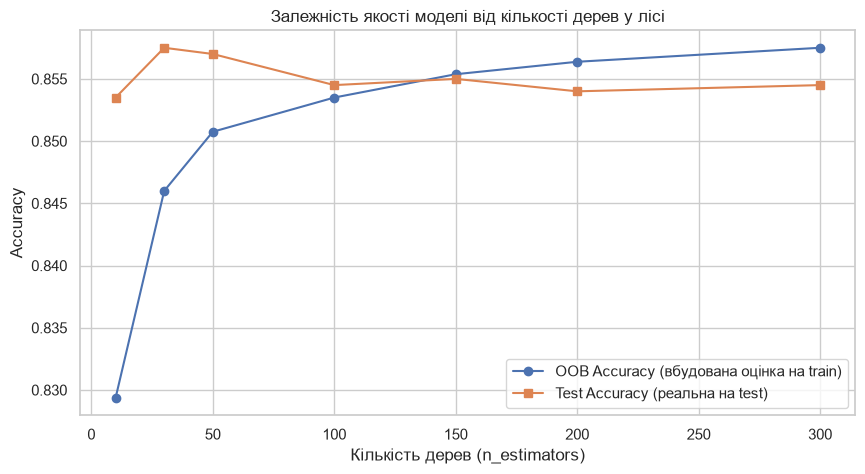

,OOB Accuracy,Test Accuracy
К-сть дерев,,
10,0.8294,0.8535
30,0.8460,0.8575
50,0.8508,0.8570
100,0.8535,0.8545
150,0.8554,0.8550
200,0.8564,0.8540
300,0.8575,0.8545


In [3]:
n_trees_list = [10, 30, 50, 100, 150, 200, 300]
oob_scores = []
test_scores = []

for n in n_trees_list:
    rf = RandomForestClassifier(n_estimators=n, oob_score=True, random_state=RANDOM_STATE, n_jobs=-1)
    rf.fit(X_train, y_train)
    
    oob_scores.append(rf.oob_score_)
    test_scores.append(accuracy_score(y_test, rf.predict(X_test)))

# Візуалізація
plt.figure(figsize=(10, 5))
plt.plot(n_trees_list, oob_scores, marker='o', color='#4C72B0', label='OOB Accuracy (вбудована оцінка на train)')
plt.plot(n_trees_list, test_scores, marker='s', color='#DD8452', label='Test Accuracy (реальна на test)')
plt.title("Залежність якості моделі від кількості дерев у лісі")
plt.xlabel("Кількість дерев (n_estimators)")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Зведення в таблицю
trees_df = pd.DataFrame({"К-сть дерев": n_trees_list, "OOB Accuracy": oob_scores, "Test Accuracy": test_scores}).set_index("К-сть дерев")
display(trees_df.round(4))

## Завдання 3. Аналіз важливості ознак
Порівняємо важливість ознак feature importance, яку вирахував випадковий ліс, із важливістю ознак одиночного оптимізованого дерева з лабораторної роботи №5. Ліс усереднює внесок ознак по всіх деревах, що робить цю оцінку значно стійкішою

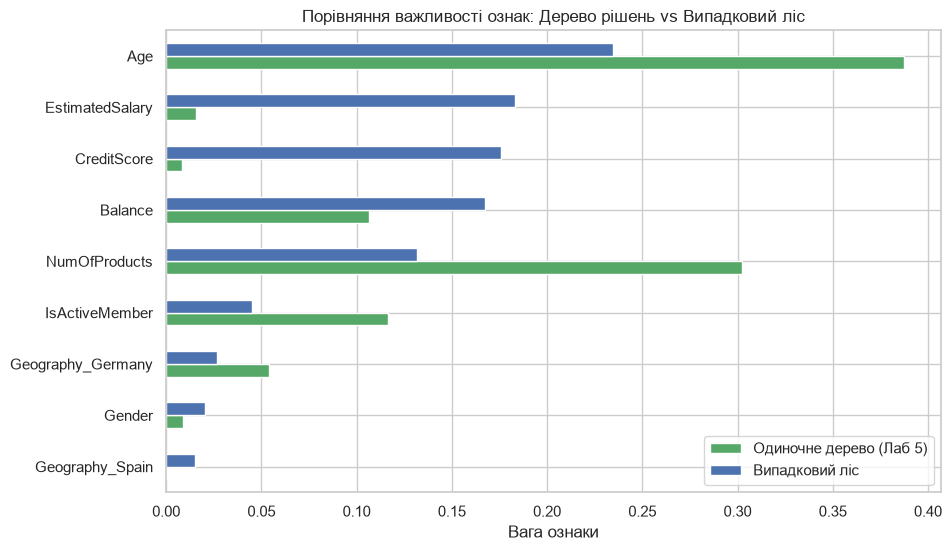

In [4]:
# Відтворимо найкраще дерево з лаб 5 для порівняння
dt_optimized = DecisionTreeClassifier(max_depth=7, min_samples_leaf=20, random_state=RANDOM_STATE)
dt_optimized.fit(X_train, y_train)

# Отримаємо найкращий ліс із попереднього циклу (300 дерев)
rf_best = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
rf_best.fit(X_train, y_train)

# Збір важливостей
importances_df = pd.DataFrame({
    "Одиночне дерево (Лаб 5)": dt_optimized.feature_importances_,
    "Випадковий ліс": rf_best.feature_importances_
}, index=X_train.columns).sort_values(by="Випадковий ліс", ascending=True)

# Візуалізація
importances_df.plot(kind='barh', figsize=(10, 6), color=['#55A868', '#4C72B0'])
plt.title("Порівняння важливості ознак: Дерево рішень vs Випадковий ліс")
plt.xlabel("Вага ознаки")
plt.show()

## Загальні висновки та відповіді на контрольні питання

**Висновки за результатами дослідження:**
* Порівняння стійкості до перенавчання показало, що одиничне дерево без обмежень ідеально завчило тренувальну вибірку Accuracy 1.0, але сильно просіло на тесті F1 0.4930. Випадковий ліс без жодних обмежень також мав Accuracy майже 1.0 на трейні, проте на тесті показав значно кращий результат F1 0.5731, що доводить його здатність зменшувати дисперсію за рахунок усереднення
* Дослідження кількості дерев довело, що зі збільшенням їхньої кількості метрики швидко зростають і після 100-150 дерев стабілізуються, не призводячи до перенавчання. Показник OOB Accuracy виявився дуже близьким до реального Test Accuracy, що дозволяє використовувати його як надійну безкоштовну крос-валідацію
* Аналіз важливості ознак показав, що одиночне дерево віддає левову частку ваги одній-двом ознакам вік і кількість продуктів, ігноруючи інші. Випадковий ліс розподіляє важливість більш рівномірно завдяки випадковому вибору підмножин ознак у кожному розбитті, що робить його оцінку набагато стійкішою до особливостей конкретної вибірки

**Відповіді на питання для самоконтролю:**
1. Ідея ансамблевого навчання полягає в комбінуванні багатьох слабко корельованих моделей для отримання підсумкового результату, який є точнішим і стійкішим за будь-яку окрему модель у складі ансамблю
2. Бутстрап-вибірка формується шляхом випадкового вибору обєктів із вихідної навчальної вибірки з поверненням, у результаті чого вона має такий самий розмір, але деякі обєкти повторюються, а близько третини не потрапляють до неї взагалі
3. Алгоритм бегінгу складається з формування багатьох бутстрап-вибірок, навчання окремої базової моделі на кожній з них та обєднання їхніх результатів шляхом голосування для класифікації або усереднення для регресії
4. Випадковий ліс відрізняється від звичайного бегінгу дерев наявністю подвійної випадковості: окрім бутстрап-вибірки обєктів, під час пошуку найкращого розбиття у кожному вузлі дерева розглядаються не всі ознаки, а лише випадкова підмножина, що робить дерева більш різноманітними
5. Важливість ознак у випадковому лісі обчислюється шляхом усереднення показників важливості зменшення неоднорідності кожної окремої ознаки по всіх деревах ансамблю
6. OOB-помилка Out-of-Bag це оцінка якості моделі на тих обєктах, які не потрапили в бутстрап-вибірку конкретного дерева. Вона безкоштовна, бо працює як вбудована крос-валідація і не вимагає окремого розбиття на train і test
7. Переваги лісу: стійкість до перенавчання, надійна оцінка важливості ознак, висока точність без підбору параметрів і наявність OOB-оцінки. Недоліки: значно нижча інтерпретованість порівняно з одиночним деревом, вищі вимоги до оперативної пам'яті та більший час передбачення